In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [2]:
def ackley(x):
    d = len(x)
    a = 20
    b = 0.2
    c = 2 * np.pi
    first_sum = np.sum(np.square(x))
    second_sum = np.sum(np.cos(np.multiply(c, x)))
    return -a*np.exp(-b*np.sqrt(first_sum / d)) - np.exp(second_sum / d) + a + np.exp(1)

In [3]:
n = 5
bounds = [(-32, 32) for _ in range(n)]

Koristeći optimizaciju rojem čestica (PSO) minimizovati Aklijevu funkciju na datom opsegu.

Napraviti klasu $Particle$ koja predstavlja jednu česticu i ima metode $updatePosition$ i $updateVelocity$ koji ažuriraju poziciju i brzinu čestice.

Za parametre $w$, $c1$ i $c2$ uzeti redom vrednosti $0.75$, $1$ i $2$.

In [4]:
class Particle:
    global_best_pos = None
    global_best_val = float('inf')
    
    def __init__(self, bounds, objective, w, c1, c2):
        self.pos = np.random.uniform(low = bounds[0][0], high = bounds[0][1], size = len(bounds))
        
        self.curr_val = objective(self.pos)
        self.objective = objective
        
        self.best_val = self.curr_val
        self.best_pos = self.pos.copy()
        
        random_point = np.random.uniform(low = bounds[0][0], high = bounds[0][1], size = len(bounds))
        self.velocity = random_point - self.pos
        
        if self.best_val < Particle.global_best_val:
            Particle.global_best_val = self.best_val
            Particle.global_best_pos = self.best_pos.copy()
            
        self.w = w
        self.c1 = c1
        self.c2 = c2
        
        self.bounds = bounds
        
    def move(self):
        self.pos += self.velocity
        self.pos = np.array([np.clip(self.pos[i], self.bounds[i][0], self.bounds[i][1]) for i in range(len(self.bounds))])
        
        self.curr_val = self.objective(self.pos)
        if self.curr_val < self.best_val:
            self.best_pos = self.pos.copy()
            self.best_val = self.curr_val
            
            if Particle.global_best_val > self.best_val:
                Particle.global_best_val = self.best_val
                Particle.global_best_pos = self.best_pos.copy()
                
        inertia = self.velocity * self.w
        cognitive_inteligence = self.c1 * (self.best_pos - self.pos) * np.random.random(size = len(self.pos))
        social_inteligence = self.c2 * (Particle.global_best_pos - self.pos) * np.random.random(size = len(self.pos))
        
        self.velocity = inertia + cognitive_inteligence + social_inteligence

In [5]:
from matplotlib import pyplot as plt

Napisati funkciju $pso$ koja pravi roj od $numParticles$ čestica i vrši optimizaciju.

Uslov zaustavljanja je broj iteracija $iters$.

Nacrtati grafik promene vrednosti najboljeg rešenja kroz iteracije.

Iz funkcije vratiti poziciju i vrednost najboljeg rešenja.

In [6]:
def pso(num_iters, swarm_size, bounds, objective, w, c1, c2):
    Particle.global_best_pos = None
    Particle.global_best_val = float('inf')
    
    swarm = [Particle(bounds, objective, w, c1, c2) for i in range(swarm_size)]
    ys = []
    
    for _ in range(num_iters):
        for particle in swarm:
            particle.move()
        ys.append(Particle.global_best_val)
    
    plt.plot(range(num_iters), ys)
    plt.show()
    return Particle.global_best_pos, Particle.global_best_val

Minimum ove funkcije je nula i dostiže se u nuli.

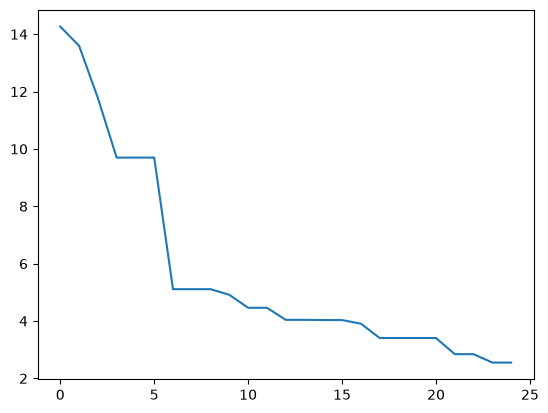

(array([-0.03267179,  0.92680881,  0.93746953,  0.10662238, -0.10049687]),
 np.float64(2.550223413326663))

In [7]:
pso(25, 300, bounds, ackley, 0.75, 1, 2)